In [1]:
from pathlib import Path
import time

import faiss
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from tensorflow.keras import Model
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam

In [2]:
current_path = Path.cwd()
project_root = current_path.parent

processed_data_dir = (
    project_root
    / "data"
    / "processed"
)

raw_data_dir = (
    project_root
    / "data"
    / "Raw"
    / "Stanford_Online_Products"
)

metadata_path = (
    processed_data_dir
    / "selected_product_metadata.csv"
)

product_metadata = pd.read_csv(
    metadata_path
)

product_metadata.shape

(3095, 12)

In [3]:
product_metadata["full_path"] = product_metadata[
    "path"
].apply(
    lambda relative_path: str(
        raw_data_dir / relative_path
    )
)

product_metadata["image_exists"] = product_metadata[
    "full_path"
].apply(
    lambda image_path: Path(image_path).exists()
)

print(
    "Total metadata rows:",
    len(product_metadata)
)

print(
    "Existing image files:",
    product_metadata["image_exists"].sum()
)

print(
    "Missing image files:",
    (~product_metadata["image_exists"]).sum()
)

Total metadata rows: 3095
Existing image files: 3095
Missing image files: 0


In [4]:
label_encoder = LabelEncoder()

encoded_labels = label_encoder.fit_transform(
    product_metadata["class_id"]
)

product_metadata["encoded_label"] = encoded_labels

number_of_classes = len(
    label_encoder.classes_
)

print(
    "Number of original product classes:",
    product_metadata["class_id"].nunique()
)

print(
    "Number of encoded classes:",
    number_of_classes
)


Number of original product classes: 600
Number of encoded classes: 600


In [5]:
train_metadata, validation_metadata = train_test_split(
    product_metadata,
    test_size=0.20,
    random_state=42,
    stratify=product_metadata["encoded_label"]
)

train_metadata = train_metadata.reset_index(drop=True)
validation_metadata = validation_metadata.reset_index(drop=True)

print("Training images:", len(train_metadata))
print("Validation images:", len(validation_metadata))

print(
    "Training classes:",
    train_metadata["encoded_label"].nunique()
)

print(
    "Validation classes:",
    validation_metadata["encoded_label"].nunique()
)

Training images: 2476
Validation images: 619
Training classes: 600
Validation classes: 600


In [6]:
image_size = (224, 224)
batch_size = 32


def load_and_preprocess_image(image_path, encoded_label):
    image_file = tf.io.read_file(image_path)

    image = tf.image.decode_jpeg(
        image_file,
        channels=3
    )

    image = tf.image.resize(
        image,
        image_size
    )

    image = tf.cast(
        image,
        tf.float32
    )

    return image, encoded_label

In [7]:
training_image_paths = train_metadata[
    "full_path"
].astype(str).values

training_labels = train_metadata[
    "encoded_label"
].astype("int32").values

validation_image_paths = validation_metadata[
    "full_path"
].astype(str).values

validation_labels = validation_metadata[
    "encoded_label"
].astype("int32").values


training_dataset = tf.data.Dataset.from_tensor_slices(
    (
        training_image_paths,
        training_labels
    )
)

validation_dataset = tf.data.Dataset.from_tensor_slices(
    (
        validation_image_paths,
        validation_labels
    )
)

In [8]:
training_dataset = (
    training_dataset
    .shuffle(
        buffer_size=len(train_metadata),
        seed=42
    )
    .map(
        load_and_preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

validation_dataset = (
    validation_dataset
    .map(
        load_and_preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

print(
    "Training batches:",
    tf.data.experimental.cardinality(
        training_dataset
    ).numpy()
)

print(
    "Validation batches:",
    tf.data.experimental.cardinality(
        validation_dataset
    ).numpy()
)

Training batches: 78
Validation batches: 20


In [9]:
data_augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip(
            mode="horizontal"
        ),
        tf.keras.layers.RandomRotation(
            factor=0.05
        ),
        tf.keras.layers.RandomZoom(
            height_factor=0.10,
            width_factor=0.10
        ),
        tf.keras.layers.RandomTranslation(
            height_factor=0.05,
            width_factor=0.05
        ),
        tf.keras.layers.RandomContrast(
            factor=0.10
        )
    ],
    name="data_augmentation"
)

print("Data augmentation pipeline created")

Data augmentation pipeline created


In [10]:
base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = tf.keras.Input(
    shape=(224, 224, 3),
    name="input_image"
)

x = data_augmentation(inputs)

x = base_model(
    x,
    training=False
)

x = Dropout(
    0.30,
    name="dropout_layer"
)(x)

embedding_output = Dense(
    512,
    activation="relu",
    name="product_embedding"
)(x)

classification_output = Dense(
    number_of_classes,
    activation="softmax",
    name="classification_output"
)(embedding_output)

fine_tuning_model = Model(
    inputs=inputs,
    outputs=classification_output
)

print("Fine-tuning model created successfully")
print("Number of classes:", number_of_classes)
print("Base model trainable:", base_model.trainable)

Fine-tuning model created successfully
Number of classes: 600
Base model trainable: False


In [11]:
fine_tuning_model.compile(
    optimizer=Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tuning_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 1280)           │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_layer (Dropout)         │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ product_embedding (Dense)       │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_output (Dense)   │ (None, 600)            │       307,800 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,013,243 (19.12 MB)

 Trainable params: 963,672 (3.68 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [12]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

reduce_learning_rate = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

In [13]:
initial_history = fine_tuning_model.fit(
    training_dataset,
    validation_data=validation_dataset,
    epochs=10,
    callbacks=[
        early_stopping,
        reduce_learning_rate
    ]
)

Epoch 1/10


c:\Users\hunte\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


78/78 ━━━━━━━━━━━━━━━━━━━━ 77s 888ms/step - accuracy: 0.0626 - loss: 6.1053 - val_accuracy: 0.2439 - val_loss: 4.8195 - learning_rate: 0.0010
Epoch 2/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 68s 876ms/step - accuracy: 0.4689 - loss: 2.8355 - val_accuracy: 0.5299 - val_loss: 2.2377 - learning_rate: 0.0010
Epoch 3/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 69s 886ms/step - accuracy: 0.7997 - loss: 0.9710 - val_accuracy: 0.6333 - val_loss: 1.7313 - learning_rate: 0.0010
Epoch 4/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 69s 881ms/step - accuracy: 0.9132 - loss: 0.4520 - val_accuracy: 0.6494 - val_loss: 1.5470 - learning_rate: 0.0010
Epoch 5/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 72s 918ms/step - accuracy: 0.9467 - loss: 0.2779 - val_accuracy: 0.6769 - val_loss: 1.5035 - learning_rate: 0.0010
Epoch 6/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 70s 900ms/step - accuracy: 0.9673 - loss: 0.2075 - val_accuracy: 0.7011 - val_loss: 1.4269 - learning_rate: 0.0010
Epoch 7/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 70s 897ms/step - accuracy: 0.9685 - loss: 0.1556 - val_

In [16]:
base_model.trainable = True

# Keep most EfficientNet layers frozen
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Allow only the last 30 layers to learn
for layer in base_model.layers[-30:]:
    layer.trainable = True

trainable_base_layers = sum(
    layer.trainable
    for layer in base_model.layers
)

print("Total EfficientNet layers:", len(base_model.layers))
print("Trainable EfficientNet layers:", trainable_base_layers)

Total EfficientNet layers: 239
Trainable EfficientNet layers: 30


In [17]:
fine_tuning_model.compile(
    optimizer=Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled for fine-tuning")

Model recompiled for fine-tuning


In [18]:
fine_tuning_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

fine_tuning_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

fine_tuning_history = fine_tuning_model.fit(
    training_dataset,
    validation_data=validation_dataset,
    epochs=10,
    callbacks=[
        fine_tuning_early_stopping,
        fine_tuning_reduce_lr
    ]
)

Epoch 1/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 92s 1s/step - accuracy: 0.9370 - loss: 0.6810 - val_accuracy: 0.7237 - val_loss: 1.3164 - learning_rate: 1.0000e-05
Epoch 2/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 78s 1s/step - accuracy: 0.9523 - loss: 0.5634 - val_accuracy: 0.7189 - val_loss: 1.3818 - learning_rate: 1.0000e-05
Epoch 3/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 80s 1s/step - accuracy: 0.9641 - loss: 0.4664 - val_accuracy: 0.7092 - val_loss: 1.4221 - learning_rate: 1.0000e-05
Epoch 4/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 80s 1s/step - accuracy: 0.9754 - loss: 0.4103 - val_accuracy: 0.7173 - val_loss: 1.4524 - learning_rate: 5.0000e-06


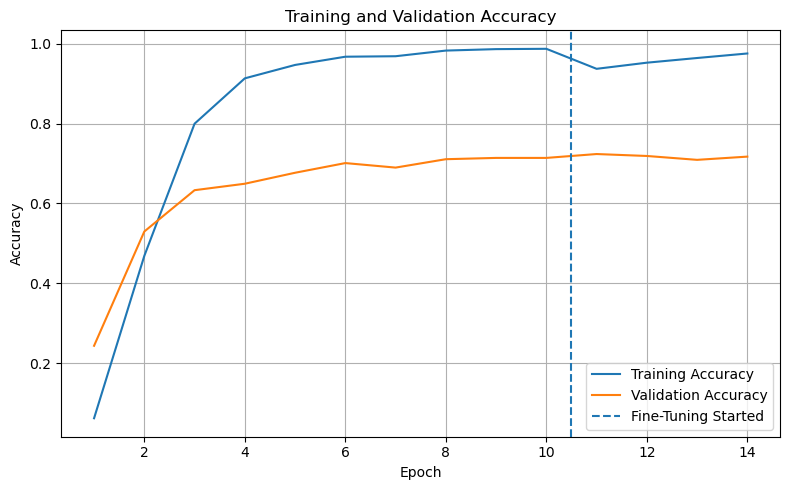

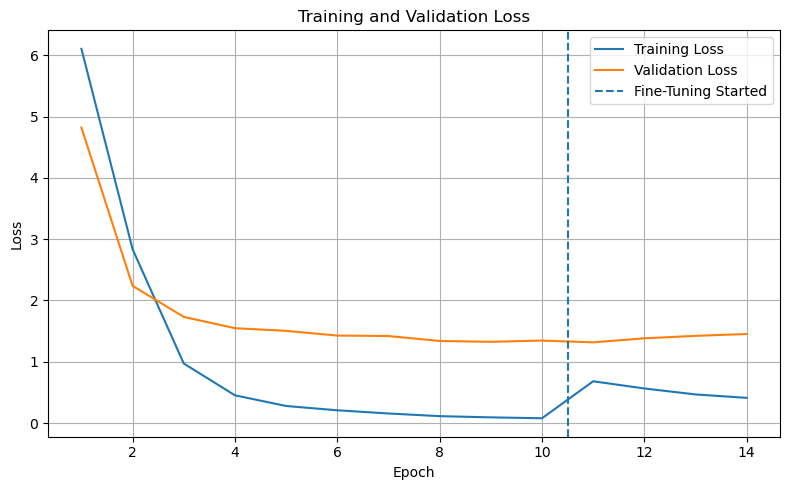

In [19]:
initial_training_accuracy = (
    initial_history.history["accuracy"]
)

initial_validation_accuracy = (
    initial_history.history["val_accuracy"]
)

initial_training_loss = (
    initial_history.history["loss"]
)

initial_validation_loss = (
    initial_history.history["val_loss"]
)


fine_tuning_training_accuracy = (
    fine_tuning_history.history["accuracy"]
)

fine_tuning_validation_accuracy = (
    fine_tuning_history.history["val_accuracy"]
)

fine_tuning_training_loss = (
    fine_tuning_history.history["loss"]
)

fine_tuning_validation_loss = (
    fine_tuning_history.history["val_loss"]
)


combined_training_accuracy = (
    initial_training_accuracy
    + fine_tuning_training_accuracy
)

combined_validation_accuracy = (
    initial_validation_accuracy
    + fine_tuning_validation_accuracy
)

combined_training_loss = (
    initial_training_loss
    + fine_tuning_training_loss
)

combined_validation_loss = (
    initial_validation_loss
    + fine_tuning_validation_loss
)


initial_epoch_count = len(
    initial_training_accuracy
)

total_epochs = range(
    1,
    len(combined_training_accuracy) + 1
)


plt.figure(figsize=(8, 5))

plt.plot(
    total_epochs,
    combined_training_accuracy,
    label="Training Accuracy"
)

plt.plot(
    total_epochs,
    combined_validation_accuracy,
    label="Validation Accuracy"
)

plt.axvline(
    x=initial_epoch_count + 0.5,
    linestyle="--",
    label="Fine-Tuning Started"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()


plt.figure(figsize=(8, 5))

plt.plot(
    total_epochs,
    combined_training_loss,
    label="Training Loss"
)

plt.plot(
    total_epochs,
    combined_validation_loss,
    label="Validation Loss"
)

plt.axvline(
    x=initial_epoch_count + 0.5,
    linestyle="--",
    label="Fine-Tuning Started"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [20]:
fine_tuning_model_path = (
    processed_data_dir
    / "fine_tuned_product_classifier.keras"
)

embedding_model_path = (
    processed_data_dir
    / "fine_tuned_embedding_model.keras"
)


fine_tuning_model.save(
    fine_tuning_model_path
)


fine_tuned_embedding_model = Model(
    inputs=fine_tuning_model.input,
    outputs=fine_tuning_model.get_layer(
        "product_embedding"
    ).output
)


fine_tuned_embedding_model.save(
    embedding_model_path
)


print(
    "Final classifier saved at:",
    fine_tuning_model_path
)

print(
    "Final embedding model saved at:",
    embedding_model_path
)

print(
    "Embedding output shape:",
    fine_tuned_embedding_model.output_shape)

Final classifier saved at: c:\Users\hunte\VS Code\Visual Product Similarity\data\processed\fine_tuned_product_classifier.keras
Final embedding model saved at: c:\Users\hunte\VS Code\Visual Product Similarity\data\processed\fine_tuned_embedding_model.keras
Embedding output shape: (None, 512)


In [21]:
all_image_paths = product_metadata[
    "full_path"
].astype(str).values

all_labels = product_metadata[
    "encoded_label"
].astype("int32").values

all_images_dataset = tf.data.Dataset.from_tensor_slices(
    (
        all_image_paths,
        all_labels
    )
)

all_images_dataset = (
    all_images_dataset
    .map(
        load_and_preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

print(
    "Total images:",
    len(all_image_paths)
)

print(
    "Total batches:",
    tf.data.experimental.cardinality(
        all_images_dataset
    ).numpy()
)

Total images: 3095
Total batches: 97


In [22]:
fine_tuned_embeddings = fine_tuned_embedding_model.predict(
    all_images_dataset,
    verbose=1
)

print(
    "Updated embeddings shape:",
    fine_tuned_embeddings.shape
)

print(
    "Contains NaN:",
    np.isnan(fine_tuned_embeddings).any()
)

print(
    "Contains infinity:",
    np.isinf(fine_tuned_embeddings).any()
)

97/97 ━━━━━━━━━━━━━━━━━━━━ 67s 673ms/step
Updated embeddings shape: (3095, 512)
Contains NaN: False
Contains infinity: False


In [23]:
fine_tuned_embedding_norms = np.linalg.norm(
    fine_tuned_embeddings,
    axis=1,
    keepdims=True
)

normalised_fine_tuned_embeddings = (
    fine_tuned_embeddings
    / np.clip(
        fine_tuned_embedding_norms,
        1e-12,
        None
    )
).astype(
    np.float32,
    copy=False
)

print(
    "Normalised fine-tuned embeddings shape:",
    normalised_fine_tuned_embeddings.shape
)

Normalised fine-tuned embeddings shape: (3095, 512)


In [24]:
fine_tuned_embeddings_path = (
    processed_data_dir
    / "fine_tuned_product_embeddings.npy"
)

np.save(
    fine_tuned_embeddings_path,
    fine_tuned_embeddings
)

print(
    "Fine-tuned embeddings saved at:",
    fine_tuned_embeddings_path
)

print(
    "File exists:",
    fine_tuned_embeddings_path.exists()
)

Fine-tuned embeddings saved at: c:\Users\hunte\VS Code\Visual Product Similarity\data\processed\fine_tuned_product_embeddings.npy
File exists: True


In [25]:
fine_tuned_faiss_index_path = (
    processed_data_dir
    / "fine_tuned_product_faiss_hnsw_index.index"
)


fine_tuned_embedding_dimension = (
    normalised_fine_tuned_embeddings.shape[1]
)

fine_tuned_faiss_index = faiss.IndexHNSWFlat(
    fine_tuned_embedding_dimension,
    32,
    faiss.METRIC_INNER_PRODUCT
)

fine_tuned_faiss_index.hnsw.efConstruction = 80
fine_tuned_faiss_index.hnsw.efSearch = 64

fine_tuned_faiss_index.add(
    normalised_fine_tuned_embeddings
)

faiss.write_index(
    fine_tuned_faiss_index,
    str(fine_tuned_faiss_index_path)
)

loaded_fine_tuned_faiss_index = faiss.read_index(
    str(fine_tuned_faiss_index_path)
)

loaded_fine_tuned_faiss_index.hnsw.efSearch = 64

print(
    "Final FAISS index saved at:",
    fine_tuned_faiss_index_path
)

print(
    "Vectors inside final index:",
    loaded_fine_tuned_faiss_index.ntotal
)

print(
    "Final index dimension:",
    loaded_fine_tuned_faiss_index.d
)

Final FAISS index saved at: c:\Users\hunte\VS Code\Visual Product Similarity\data\processed\fine_tuned_product_faiss_hnsw_index.index
Vectors inside final index: 3095
Final index dimension: 512


In [26]:
def calculate_exact_product_precision_recall_at_k(
    query_index,
    faiss_index,
    normalised_embeddings,
    product_metadata,
    top_k=3
):
    query_embedding = normalised_embeddings[
        query_index:query_index + 1
    ]

    _, neighbour_indices = faiss_index.search(
        query_embedding,
        top_k + 1
    )

    retrieved_indices = [
        int(index)
        for index in neighbour_indices[0]
        if int(index) != query_index
    ][:top_k]

    query_class_id = product_metadata.iloc[
        query_index
    ]["class_id"]

    retrieved_class_ids = product_metadata.iloc[
        retrieved_indices
    ]["class_id"]

    relevant_retrieved = (
        retrieved_class_ids == query_class_id
    ).sum()

    total_relevant = (
        product_metadata["class_id"]
        == query_class_id
    ).sum() - 1

    precision_at_k = relevant_retrieved / top_k

    recall_at_k = (
        relevant_retrieved / total_relevant
        if total_relevant > 0
        else 0
    )

    return precision_at_k, recall_at_k


exact_product_evaluation_at_3_results = []

top_k = 3

for query_index in range(len(product_metadata)):

    precision_at_3, recall_at_3 = (
        calculate_exact_product_precision_recall_at_k(
            query_index=query_index,
            faiss_index=loaded_fine_tuned_faiss_index,
            normalised_embeddings=normalised_fine_tuned_embeddings,
            product_metadata=product_metadata,
            top_k=top_k
        )
    )

    query_row = product_metadata.iloc[
        query_index
    ]

    exact_product_evaluation_at_3_results.append(
        {
            "query_index": query_index,
            "image_id": query_row["image_id"],
            "class_id": query_row["class_id"],
            "category_name": query_row["category_name"],
            "exact_product_precision_at_3": precision_at_3,
            "exact_product_recall_at_3": recall_at_3
        }
    )

exact_product_evaluation_at_3_df = pd.DataFrame(
    exact_product_evaluation_at_3_results
)

average_exact_product_precision_at_3 = (
    exact_product_evaluation_at_3_df[
        "exact_product_precision_at_3"
    ].mean()
)

average_exact_product_recall_at_3 = (
    exact_product_evaluation_at_3_df[
        "exact_product_recall_at_3"
    ].mean()
)

print(
    "Fine-Tuned Exact-Product Precision@3:",
    average_exact_product_precision_at_3
)

print(
    "Fine-Tuned Exact-Product Recall@3:",
    average_exact_product_recall_at_3
)

print(
    "Evaluation shape:",
    exact_product_evaluation_at_3_df.shape
)

Fine-Tuned Exact-Product Precision@3: 0.5946149703823371
Fine-Tuned Exact-Product Recall@3: 0.4226655896607432
Evaluation shape: (3095, 6)


In [27]:
def calculate_category_filtered_exact_product_metrics_at_k(
    query_index,
    faiss_index,
    normalised_embeddings,
    product_metadata,
    top_k=3
):
    query_embedding = normalised_embeddings[
        query_index:query_index + 1
    ]

    query_category = product_metadata.iloc[
        query_index
    ]["category_name"]

    query_class_id = product_metadata.iloc[
        query_index
    ]["class_id"]

    search_k = min(
        len(product_metadata),
        top_k * 50
    )

    _, neighbour_indices = faiss_index.search(
        query_embedding,
        search_k
    )

    filtered_indices = []

    for neighbour_index in neighbour_indices[0]:
        neighbour_index = int(neighbour_index)

        if neighbour_index == query_index:
            continue

        neighbour_category = product_metadata.iloc[
            neighbour_index
        ]["category_name"]

        if neighbour_category != query_category:
            continue

        filtered_indices.append(
            neighbour_index
        )

        if len(filtered_indices) == top_k:
            break

    retrieved_class_ids = product_metadata.iloc[
        filtered_indices
    ]["class_id"]

    relevant_retrieved = (
        retrieved_class_ids == query_class_id
    ).sum()

    total_relevant = (
        product_metadata["class_id"]
        == query_class_id
    ).sum() - 1

    retrieved_count = len(
        filtered_indices
    )

    precision_at_k = (
        relevant_retrieved / retrieved_count
        if retrieved_count > 0
        else 0
    )

    recall_at_k = (
        relevant_retrieved / total_relevant
        if total_relevant > 0
        else 0
    )

    return precision_at_k, recall_at_k

In [28]:
filtered_evaluation_at_3_results = []

top_k = 3

for query_index in range(len(product_metadata)):

    filtered_precision_at_3, filtered_recall_at_3 = (
        calculate_category_filtered_exact_product_metrics_at_k(
            query_index=query_index,
            faiss_index=loaded_fine_tuned_faiss_index,
            normalised_embeddings=normalised_fine_tuned_embeddings,
            product_metadata=product_metadata,
            top_k=top_k
        )
    )

    query_row = product_metadata.iloc[
        query_index
    ]

    filtered_evaluation_at_3_results.append(
        {
            "query_index": query_index,
            "image_id": query_row["image_id"],
            "class_id": query_row["class_id"],
            "category_name": query_row["category_name"],
            "filtered_exact_product_precision_at_3": (
                filtered_precision_at_3
            ),
            "filtered_exact_product_recall_at_3": (
                filtered_recall_at_3
            )
        }
    )

filtered_evaluation_at_3_df = pd.DataFrame(
    filtered_evaluation_at_3_results
)

average_filtered_precision_at_3 = (
    filtered_evaluation_at_3_df[
        "filtered_exact_product_precision_at_3"
    ].mean()
)

average_filtered_recall_at_3 = (
    filtered_evaluation_at_3_df[
        "filtered_exact_product_recall_at_3"
    ].mean()
)

print(
    "Unfiltered Fine-Tuned Exact-Product Precision@3:",
    average_exact_product_precision_at_3
)

print(
    "Category-Filtered Exact-Product Precision@3:",
    average_filtered_precision_at_3
)

print()

print(
    "Unfiltered Fine-Tuned Exact-Product Recall@3:",
    average_exact_product_recall_at_3
)

print(
    "Category-Filtered Exact-Product Recall@3:",
    average_filtered_recall_at_3
)

print(
    "\nFiltered evaluation shape:",
    filtered_evaluation_at_3_df.shape
)

Unfiltered Fine-Tuned Exact-Product Precision@3: 0.5946149703823371
Category-Filtered Exact-Product Precision@3: 0.6328486806677436

Unfiltered Fine-Tuned Exact-Product Recall@3: 0.4226655896607432
Category-Filtered Exact-Product Recall@3: 0.45101238556812057

Filtered evaluation shape: (3095, 6)


In [29]:
def calculate_category_precision_recall_at_k(
    query_index,
    faiss_index,
    normalised_embeddings,
    product_metadata,
    top_k=3
):
    # Take the query image embedding
    query_embedding = normalised_embeddings[
        query_index:query_index + 1
    ]

    # Search one extra result because the query image itself
    # is usually returned as the closest result
    _, neighbour_indices = faiss_index.search(
        query_embedding,
        top_k + 1
    )

    # Remove the query image itself
    retrieved_indices = [
        int(index)
        for index in neighbour_indices[0]
        if int(index) != query_index
    ][:top_k]

    # Category of the query image
    query_category = product_metadata.iloc[
        query_index
    ]["category_name"]

    # Categories of retrieved images
    retrieved_categories = product_metadata.iloc[
        retrieved_indices
    ]["category_name"]

    # Count how many retrieved images belong
    # to the same category as the query
    relevant_retrieved = (
        retrieved_categories == query_category
    ).sum()

    # Total number of other images available
    # from the same category
    total_relevant = (
        product_metadata["category_name"] == query_category
    ).sum() - 1

    category_precision_at_k = (
        relevant_retrieved / top_k
    )

    category_recall_at_k = (
        relevant_retrieved / total_relevant
        if total_relevant > 0
        else 0
    )

    return (
        category_precision_at_k,
        category_recall_at_k
    )

In [30]:
category_evaluation_at_3_results = []

top_k = 3

for query_index in range(len(product_metadata)):

    category_precision_at_3, category_recall_at_3 = (
        calculate_category_precision_recall_at_k(
            query_index=query_index,
            faiss_index=loaded_fine_tuned_faiss_index,
            normalised_embeddings=normalised_fine_tuned_embeddings,
            product_metadata=product_metadata,
            top_k=top_k
        )
    )

    query_row = product_metadata.iloc[query_index]

    category_evaluation_at_3_results.append(
        {
            "query_index": query_index,
            "image_id": query_row["image_id"],
            "class_id": query_row["class_id"],
            "category_name": query_row["category_name"],
            "category_precision_at_3": category_precision_at_3,
            "category_recall_at_3": category_recall_at_3
        }
    )

category_evaluation_at_3_df = pd.DataFrame(
    category_evaluation_at_3_results
)

print(
    "Category evaluation shape:",
    category_evaluation_at_3_df.shape
)

category_evaluation_at_3_df.head()

Category evaluation shape: (3095, 6)


,query_index,image_id,class_id,category_name,category_precision_at_3,category_recall_at_3
0,0,84,16,bicycle,1.0,0.012048
1,1,85,16,bicycle,1.0,0.012048
2,2,86,16,bicycle,1.0,0.012048
3,3,87,16,bicycle,1.0,0.012048
4,4,129,25,bicycle,1.0,0.012048


In [31]:
average_category_precision_at_3 = (
    category_evaluation_at_3_df[
        "category_precision_at_3"
    ].mean()
)

average_category_recall_at_3 = (
    category_evaluation_at_3_df[
        "category_recall_at_3"
    ].mean()
)

print(
    "Average Category Precision@3:",
    average_category_precision_at_3
)

print(
    "Average Category Recall@3:",
    average_category_recall_at_3
)

Average Category Precision@3: 0.8666666666666666
Average Category Recall@3: 0.010119790855664503


In [32]:
category_performance_df = (
    category_evaluation_at_3_df
    .groupby("category_name")
    .agg(
        number_of_queries=(
            "query_index",
            "count"
        ),
        average_category_precision_at_3=(
            "category_precision_at_3",
            "mean"
        ),
        average_category_recall_at_3=(
            "category_recall_at_3",
            "mean"
        )
    )
    .reset_index()
    .sort_values(
        "average_category_precision_at_3",
        ascending=False
    )
)

category_performance_df

,category_name,number_of_queries,average_category_precision_at_3,average_category_recall_at_3
0,bicycle,250,0.960000,0.011566
7,mug,264,0.953283,0.010874
8,sofa,260,0.923077,0.010692
9,stapler,263,0.869455,0.009956
1,cabinet,265,0.865409,0.009834
3,coffee_maker,260,0.855128,0.009905
5,kettle,259,0.849421,0.009877
10,table,259,0.846847,0.009847
4,fan,244,0.842896,0.010406
2,chair,263,0.833967,0.009549


In [33]:
top_k = 3

loaded_fine_tuned_faiss_index.search(
    normalised_fine_tuned_embeddings[0:1],
    top_k + 1
)

search_times_ms = []

for query_index in range(len(product_metadata)):

    query_embedding = normalised_fine_tuned_embeddings[
        query_index:query_index + 1
    ]

    start_time = time.perf_counter()

    loaded_fine_tuned_faiss_index.search(
        query_embedding,
        top_k + 1
    )

    end_time = time.perf_counter()

    search_times_ms.append(
        (end_time - start_time) * 1000
    )

average_search_time_ms = np.mean(
    search_times_ms
)

median_search_time_ms = np.median(
    search_times_ms
)

maximum_search_time_ms = np.max(
    search_times_ms
)

print(
    "Average FAISS-only search time:",
    average_search_time_ms,
    "ms"
)

print(
    "Median FAISS-only search time:",
    median_search_time_ms,
    "ms"
)

print(
    "Maximum FAISS-only search time:",
    maximum_search_time_ms,
    "ms"
)

Average FAISS-only search time: 0.054918254630847776 ms
Median FAISS-only search time: 0.05350005812942982 ms
Maximum FAISS-only search time: 0.19580009393393993 ms


In [34]:
def display_category_retrieval_results(
    query_index,
    faiss_index,
    normalised_embeddings,
    product_metadata,
    top_k=3
):
    query_embedding = normalised_embeddings[
        query_index:query_index + 1
    ]

    similarity_scores, neighbour_indices = (
        faiss_index.search(
            query_embedding,
            top_k + 1
        )
    )

    retrieved_indices = []
    retrieved_scores = []

    for neighbour_index, similarity_score in zip(
        neighbour_indices[0],
        similarity_scores[0]
    ):
        neighbour_index = int(neighbour_index)

        if neighbour_index == query_index:
            continue

        retrieved_indices.append(neighbour_index)
        retrieved_scores.append(float(similarity_score))

        if len(retrieved_indices) == top_k:
            break

    query_row = product_metadata.iloc[query_index]

    figure, axes = plt.subplots(
        1,
        top_k + 1,
        figsize=(16, 4)
    )

    query_image = Image.open(
        query_row["full_path"]
    ).convert("RGB")

    axes[0].imshow(query_image)
    axes[0].set_title(
        f"Query\n"
        f"Category: {query_row['category_name']}\n"
        f"Class ID: {query_row['class_id']}"
    )
    axes[0].axis("off")

    for position, (
        retrieved_index,
        similarity_score
    ) in enumerate(
        zip(
            retrieved_indices,
            retrieved_scores
        ),
        start=1
    ):
        retrieved_row = product_metadata.iloc[
            retrieved_index
        ]

        retrieved_image = Image.open(
            retrieved_row["full_path"]
        ).convert("RGB")

        category_match = (
            retrieved_row["category_name"]
            == query_row["category_name"]
        )

        axes[position].imshow(retrieved_image)

        axes[position].set_title(
            f"Rank {position}\n"
            f"Category: {retrieved_row['category_name']}\n"
            f"Class ID: {retrieved_row['class_id']}\n"
            f"Score: {similarity_score:.4f}\n"
            f"Category Match: {category_match}"
        )

        axes[position].axis("off")

    plt.tight_layout()
    plt.show()

In [35]:
bicycle_query_index = product_metadata.index[
    product_metadata["category_name"] == "bicycle"
][0]

coffee_maker_query_index = product_metadata.index[
    product_metadata["category_name"] == "coffee_maker"
][0]

lamp_query_index = product_metadata.index[
    product_metadata["category_name"] == "lamp"
][0]

print("Bicycle query index:", bicycle_query_index)
print("Coffee-maker query index:", coffee_maker_query_index)
print("Lamp query index:", lamp_query_index)

Bicycle query index: 0
Coffee-maker query index: 778
Lamp query index: 1541


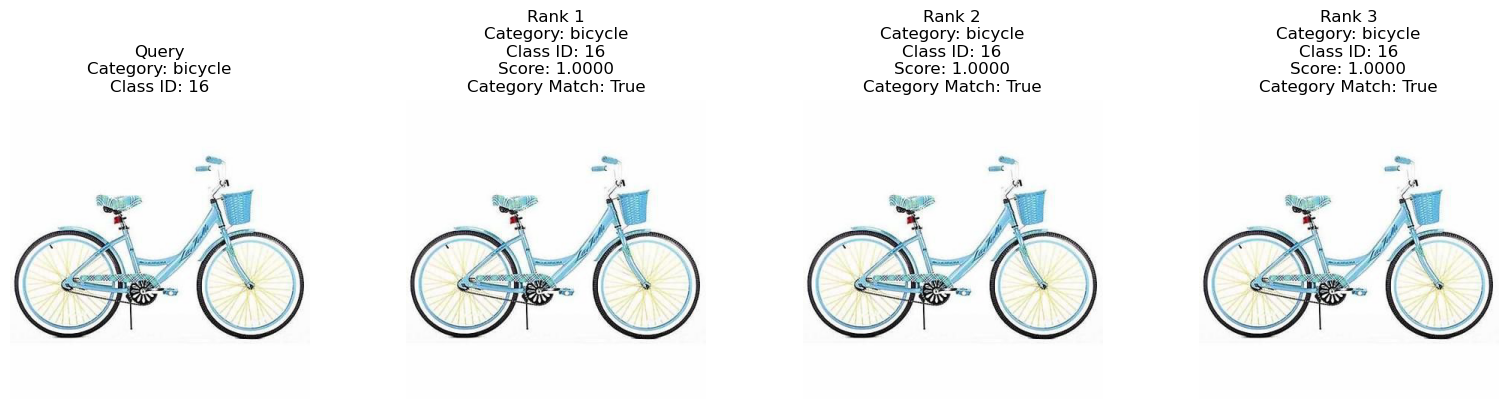

In [36]:
display_category_retrieval_results(
    query_index=bicycle_query_index,
    faiss_index=loaded_fine_tuned_faiss_index,
    normalised_embeddings=normalised_fine_tuned_embeddings,
    product_metadata=product_metadata,
    top_k=3
)

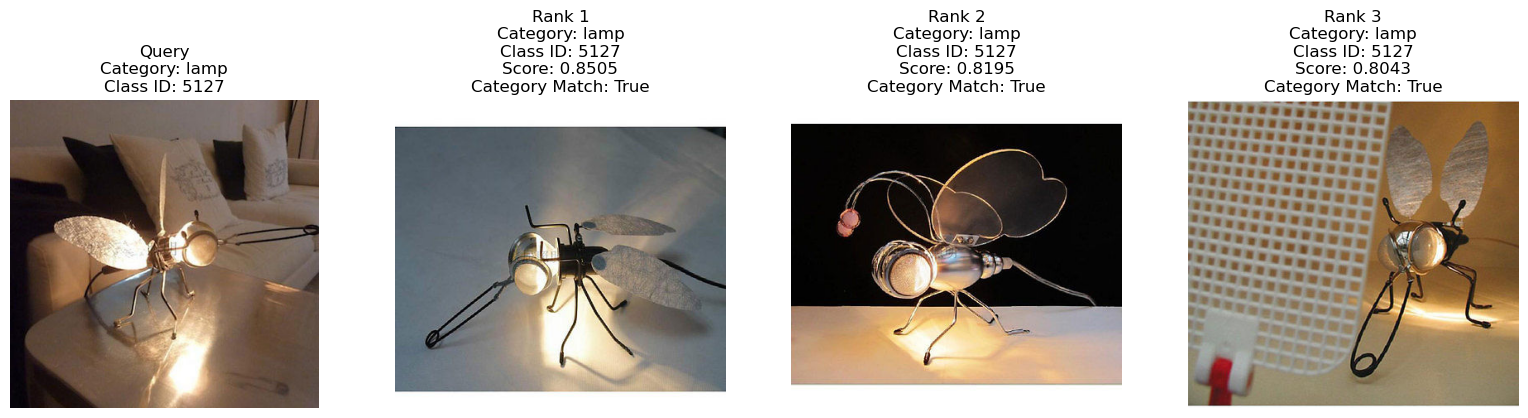

In [37]:
display_category_retrieval_results(
    query_index=lamp_query_index,
    faiss_index=loaded_fine_tuned_faiss_index,
    normalised_embeddings=normalised_fine_tuned_embeddings,
    product_metadata=product_metadata,
    top_k=3
)

In [38]:
category_evaluation_path = (
    processed_data_dir
    / "category_evaluation_at_3.csv"
)

category_performance_path = (
    processed_data_dir
    / "category_wise_performance_at_3.csv"
)

category_evaluation_at_3_df.to_csv(
    category_evaluation_path,
    index=False
)

category_performance_df.to_csv(
    category_performance_path,
    index=False
)

print(
    "Category evaluation saved at:",
    category_evaluation_path
)

print(
    "Category-wise performance saved at:",
    category_performance_path
)

Category evaluation saved at: c:\Users\hunte\VS Code\Visual Product Similarity\data\processed\category_evaluation_at_3.csv
Category-wise performance saved at: c:\Users\hunte\VS Code\Visual Product Similarity\data\processed\category_wise_performance_at_3.csv
